<a href="https://colab.research.google.com/github/srihari101107-ai/Karateclub_graphtheory/blob/main/Karate_Modularity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modularity on the Karate Club Graph
**DSC212: Graph Theory – Research Assignment**

**Name:** M Sri Hari Venkatesh
**Roll No.:** IMS25207

This notebook implements **recursive spectral modularity partitioning** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, following Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.

**Plan**
1. Build $A$, $k$, $m$ and the modularity matrix $B = A - \frac{kk^\top}{2m}$; sanity-check its properties.
2. Spectral bisection with the leading eigenvector, recursive splitting with the stopping rule $\lambda_1^{(C)} \le 0$.
3. Visualise the graph after every split (fixed layout, one colour per community).
4. After every split compute degree / betweenness / closeness centrality and clustering, and plot how they evolve.
5. Discussion.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl
from collections import deque

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 110

## 1. Data and the modularity matrix
NetworkX ships Zachary's graph (34 nodes, 78 edges). Each node carries a `club` attribute (`'Mr. Hi'` or `'Officer'`) recording which faction it actually joined after the split – this is our ground truth, **never used by the algorithm**.

In [2]:
G = nx.karate_club_graph()
# Newer NetworkX versions attach interaction-count weights; the handout uses the plain 0/1 graph.
for _, _, d in G.edges(data=True):
    d.pop("weight", None)
nodes = sorted(G.nodes())                     # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n}, m = {m}")

# Adjacency matrix (rows/cols ordered as `nodes`), degree vector, modularity matrix
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # n x n, entries in {0,1} (ignore the edge weights newer NetworkX attaches)
k = A.sum(axis=1)                             # degree vector
B = A - np.outer(k, k) / (2 * m)              # B = A - k k^T / 2m

truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes])
print("Ground truth sizes  (Mr. Hi, Officer):", np.bincount(truth))

n = 34, m = 78
Ground truth sizes  (Mr. Hi, Officer): [17 17]


### Sanity checks (Proposition 1, Proposition 2, Corollary 1)
* $B$ is real symmetric.
* $B\mathbf 1 = 0$, so $0$ is always an eigenvalue of the *global* $B$.
* The trivial partition has $Q=0$.

In [3]:
print("B symmetric            :", np.allclose(B, B.T))
print("||B 1||                :", np.linalg.norm(B @ np.ones(n)))
print("Q(trivial) = 1^T B 1/4m:", np.ones(n) @ B @ np.ones(n) / (4 * m))

evals = np.linalg.eigvalsh(B)                 # ascending
print("Largest 3 eigenvalues of B:", evals[::-1][:3])

B symmetric            : True
||B 1||                : 1.699448305951993e-15
Q(trivial) = 1^T B 1/4m: 1.120898246015783e-17
Largest 3 eigenvalues of B: [4.9771 3.0428 2.3202]


## 2. Modularity of an arbitrary partition
For $r$ communities the modularity is
$$Q=\frac{1}{2m}\sum_{c}\sum_{i,j\in c}B_{ij},$$
which reduces to $\frac1{4m}s^\top B s$ for two groups (up to the constant $\frac{1}{2m}\mathbf 1^\top B\mathbf 1 = 0$). We implement it and cross-check against NetworkX's built-in function.

In [4]:
def modularity(communities, B, m):
    # Q = (1/2m) * sum over communities of the sum of B_ij inside the community.
    # `communities` is a list of lists of node indices.
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)

# check against networkx on the ground-truth split
gt = [list(np.where(truth == c)[0]) for c in (0, 1)]
print("Q (ours, ground-truth split)    :", round(modularity(gt, B, m), 6))
print("Q (networkx, ground-truth split):", round(nx.community.modularity(G, [set(c) for c in gt]), 6))

Q (ours, ground-truth split)    : 0.358235
Q (networkx, ground-truth split): 0.358235


## 3. Spectral bisection and recursive splitting

**Restricted matrix.** For a group $C$ the handout defines $B^{(C)}$ as the block of $B$ indexed by $C$:
`B[np.ix_(C, C)]`.

> **Note (a subtlety worth knowing for the exam).** Newman's paper shows that the *exact* modularity change from splitting $C$ uses the **generalised** matrix
> $B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$ (the diagonal is corrected by the row sums of the block). For the full graph the row sums are zero ($B\mathbf 1=0$), so the two coincide; for a proper subgroup they do not, and the plain block's row sums are generally non-zero.
> The handout uses the plain block, so that is our **default** (`generalized=False`). The function also supports `generalized=True` and we compare both at the end.

**Algorithm (per group $C$).**
1. Build $B^{(C)}$, compute eigenpairs with `numpy.linalg.eigh` (symmetric ⇒ real eigenvalues, orthonormal eigenvectors).
2. If $\lambda_1^{(C)}\le 0$ (numerical tolerance `1e-10`): stop, $C$ is indivisible.
3. Otherwise $s_i=+1$ if $(u_1)_i>0$ else $-1$; split into $C^+$, $C^-$. If one side is empty the split is trivial ⇒ stop.
4. **Safeguard:** $\lambda_1>0$ only guarantees a gain for the *relaxed* real-valued vector; after rounding to $\pm1$ we also verify that the true modularity change $\Delta Q=\frac{1}{2m}\big(\sum_{C^+}B_{ij}+\sum_{C^-}B_{ij}-\sum_{C}B_{ij}\big)$ is positive, otherwise we do not split (Newman does the same).

In [5]:
TOL = 1e-10

def restricted_B(C, B, generalized=False):
    # Restricted modularity matrix B^(C) (|C| x |C|).
    BC = B[np.ix_(C, C)].copy()
    if generalized:                           # Newman's exact correction
        BC -= np.diag(BC.sum(axis=1))
    return BC

def bisect(C, B, m_total, generalized=False):
    # Try to split group C. Returns (C_plus, C_minus, lambda1); parts are None if no split.
    BC = restricted_B(C, B, generalized)
    w, V = np.linalg.eigh(BC)                 # ascending eigenvalues
    lam1, u1 = w[-1], V[:, -1]
    if lam1 <= TOL:
        return None, None, lam1
    s = np.where(u1 > 0, 1, -1)               # threshold at 0
    Cp = [c for c, si in zip(C, s) if si == 1]
    Cm = [c for c, si in zip(C, s) if si == -1]
    if len(Cp) == 0 or len(Cm) == 0:          # degenerate (all same sign)
        return None, None, lam1
    # Safeguard (as in Newman 2006): lambda1 > 0 only guarantees that a *relaxed* (real-valued)
    # vector gains modularity. After rounding to +-1 we check the true change in Q.
    dQ = (B[np.ix_(Cp, Cp)].sum() + B[np.ix_(Cm, Cm)].sum() - B[np.ix_(C, C)].sum()) / (2 * m_total)
    if dQ <= TOL:
        return None, None, lam1
    return Cp, Cm, lam1

In [6]:
def recursive_bisection(B, m, generalized=False):
    # Recursive spectral modularity partitioning.
    # One *split* = one iteration. Groups are processed first-in-first-out, so
    # splits happen level by level. Returns a list of snapshots (iteration 0 = no split).
    n = B.shape[0]
    final, queue = [], deque([list(range(n))])
    history = [dict(iter=0, communities=[list(range(n))], Q=0.0, note="start: one community")]
    it = 0
    while queue:
        C = queue.popleft()
        Cp, Cm, lam1 = bisect(C, B, m, generalized)
        if Cp is None:
            final.append(C)
            print(f"  group of size {len(C):2d}: lambda1 = {lam1:+.4f} -> indivisible")
            continue
        it += 1
        queue.extend([Cp, Cm])
        comms = [g for g in list(queue) + final]
        Q = modularity(comms, B, m)
        history.append(dict(iter=it, communities=[sorted(g) for g in comms], Q=Q,
                            note=f"split size {len(C)} (lambda1={lam1:.3f}) -> {len(Cp)} + {len(Cm)}"))
        print(f"iter {it}: split group of size {len(C):2d} (lambda1 = {lam1:+.4f}) -> {len(Cp)} + {len(Cm)};  Q = {Q:.4f}")
    return history, [sorted(c) for c in final]

print("=== Handout version (plain block B^(C)) ===")
history, final_comms = recursive_bisection(B, m, generalized=False)
print("\nFinal communities:")
for i, c in enumerate(sorted(final_comms, key=lambda c: c[0])):
    print(f"  C{i+1} (size {len(c)}): {c}")
print("Final Q =", round(modularity(final_comms, B, m), 4))

=== Handout version (plain block B^(C)) ===
iter 1: split group of size 34 (lambda1 = +4.9771) -> 16 + 18;  Q = 0.3715
iter 2: split group of size 16 (lambda1 = +2.9441) -> 10 + 6;  Q = 0.3898
iter 3: split group of size 18 (lambda1 = +2.5041) -> 5 + 13;  Q = 0.4081
  group of size 10: lambda1 = +2.5712 -> indivisible
iter 4: split group of size  6 (lambda1 = +2.1480) -> 1 + 5;  Q = 0.4094
  group of size  5: lambda1 = +1.8759 -> indivisible
  group of size 13: lambda1 = +2.3563 -> indivisible
  group of size  1: lambda1 = -0.0064 -> indivisible
  group of size  5: lambda1 = +2.1470 -> indivisible

Final communities:
  C1 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C2 (size 5): [4, 5, 6, 10, 16]
  C3 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C4 (size 1): [11]
  C5 (size 5): [24, 25, 27, 28, 31]
Final Q = 0.4094


### First split vs. ground truth
Does the very first bisection recover the real club split?

In [7]:
first = history[1]["communities"]
pred = np.zeros(n, dtype=int)
for lab, c in enumerate(first):
    pred[c] = lab
# label permutation: choose the better matching
acc = max((pred == truth).mean(), (pred != truth).mean())
mis = np.where(pred != truth)[0] if (pred == truth).mean() >= (pred != truth).mean() else np.where(pred == truth)[0]
print(f"Agreement with real split: {acc:.1%}  ({int(round(acc*n))}/{n} nodes)")
print("Misclassified node(s):", [int(v) for v in mis])

Agreement with real split: 97.1%  (33/34 nodes)
Misclassified node(s): [8]


## 4. Visualisation after every split
A single spring layout (fixed seed) is reused for every picture so only the colours change. Nodes are labelled by ID.

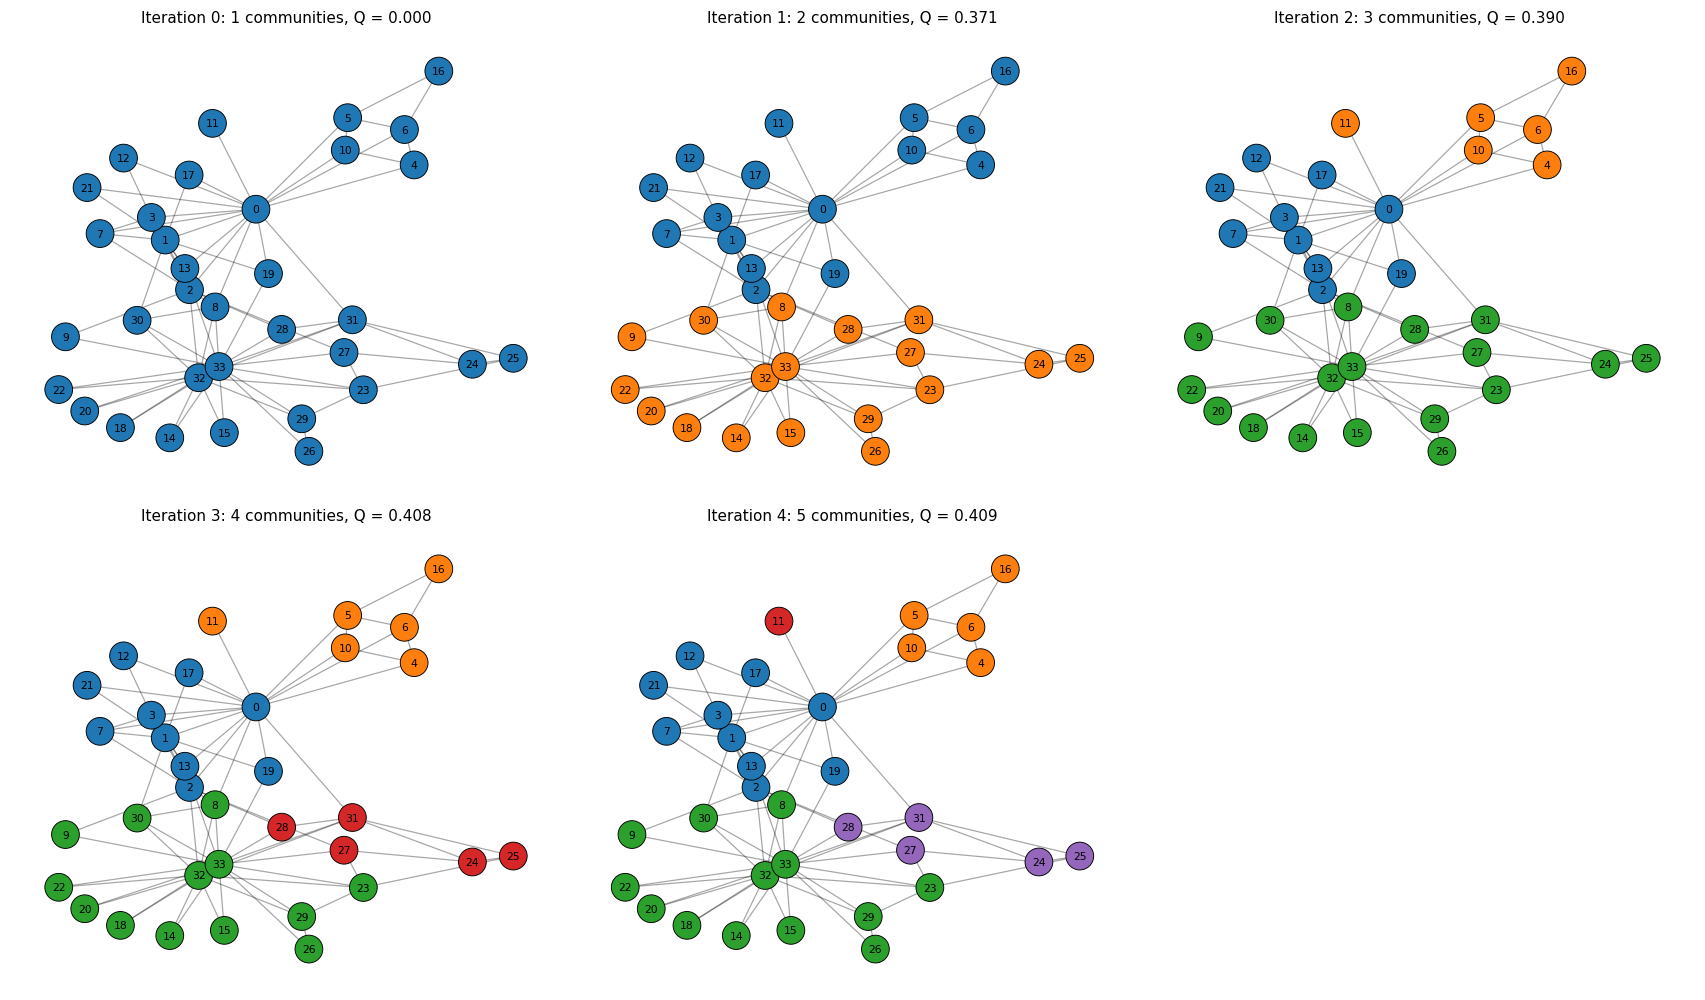

In [8]:
pos = nx.spring_layout(G, seed=42)            # fixed layout, reused everywhere
palette = list(mpl.colormaps["tab10"].colors)

def community_labels(communities):
    # node -> community id, ordering communities by smallest node ID for stable colours
    lab = {}
    for cid, c in enumerate(sorted(communities, key=min)):
        for v in c:
            lab[v] = cid
    return lab

def draw_partition(ax, communities, title):
    lab = community_labels(communities)
    colors = [palette[lab[v] % len(palette)] for v in nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=330, edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

ncols = 3
nrows = int(np.ceil(len(history) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.6 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, h in zip(axes, history):
    draw_partition(ax, h["communities"],
                   f"Iteration {h['iter']}: {len(h['communities'])} communities, Q = {h['Q']:.3f}")
for ax in axes[len(history):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("partition_evolution.png", bbox_inches="tight")
plt.show()

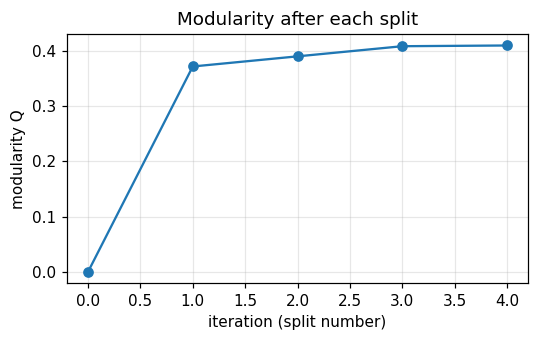

In [9]:
# Modularity as a function of iteration
plt.figure(figsize=(5, 3.2))
plt.plot([h["iter"] for h in history], [h["Q"] for h in history], "o-")
plt.xlabel("iteration (split number)"); plt.ylabel("modularity Q")
plt.title("Modularity after each split"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("modularity_vs_iteration.png"); plt.show()

## 5. Node metrics after each split
**Interpretation used.** The four NetworkX metrics computed on the *whole* graph never change when we merely recolour it, so there would be nothing to plot. To capture how the community structure affects each node, after every split we compute each metric **inside the node's current community**, i.e. on the induced subgraph $G[C]$ containing the node. Iteration 0 is therefore the ordinary whole-graph metric, and later iterations show how each node looks from within its own community.

Implementation notes: NetworkX's definitions are used unchanged (`degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`). Inside a smaller subgraph the normalisers ($n_C-1$) shrink, so values can rise even though the node's degree can only fall; a one-node community gets degree centrality 1 by NetworkX convention and 0 for the others.

In [10]:
metric_funcs = {
    "degree centrality":      nx.degree_centrality,
    "betweenness centrality": nx.betweenness_centrality,
    "closeness centrality":   nx.closeness_centrality,
    "clustering coefficient": nx.clustering,
}

def metrics_for_partition(communities):
    # Compute every metric on each community's induced subgraph.
    out = {name: {} for name in metric_funcs}
    for c in communities:
        sub = G.subgraph(c)
        for name, f in metric_funcs.items():
            out[name].update(f(sub))
    return out

# metric_history[metric][iteration] -> {node: value}
metric_history = {name: {} for name in metric_funcs}
for h in history:
    res = metrics_for_partition(h["communities"])
    for name in metric_funcs:
        metric_history[name][h["iter"]] = res[name]

# Quick check: iteration 0 must equal the plain whole-graph NetworkX values
for name, f in metric_funcs.items():
    ref = f(G)
    assert all(abs(ref[v] - metric_history[name][0][v]) < 1e-12 for v in nodes), name
print("Iteration-0 values match whole-graph NetworkX results.")

Iteration-0 values match whole-graph NetworkX results.


## 6. Evolution of the metrics
For each metric: left, every node's trajectory (grey) with the five nodes that have the highest **mean** value highlighted and labelled; right, a heat-map of all 34 nodes × iterations.

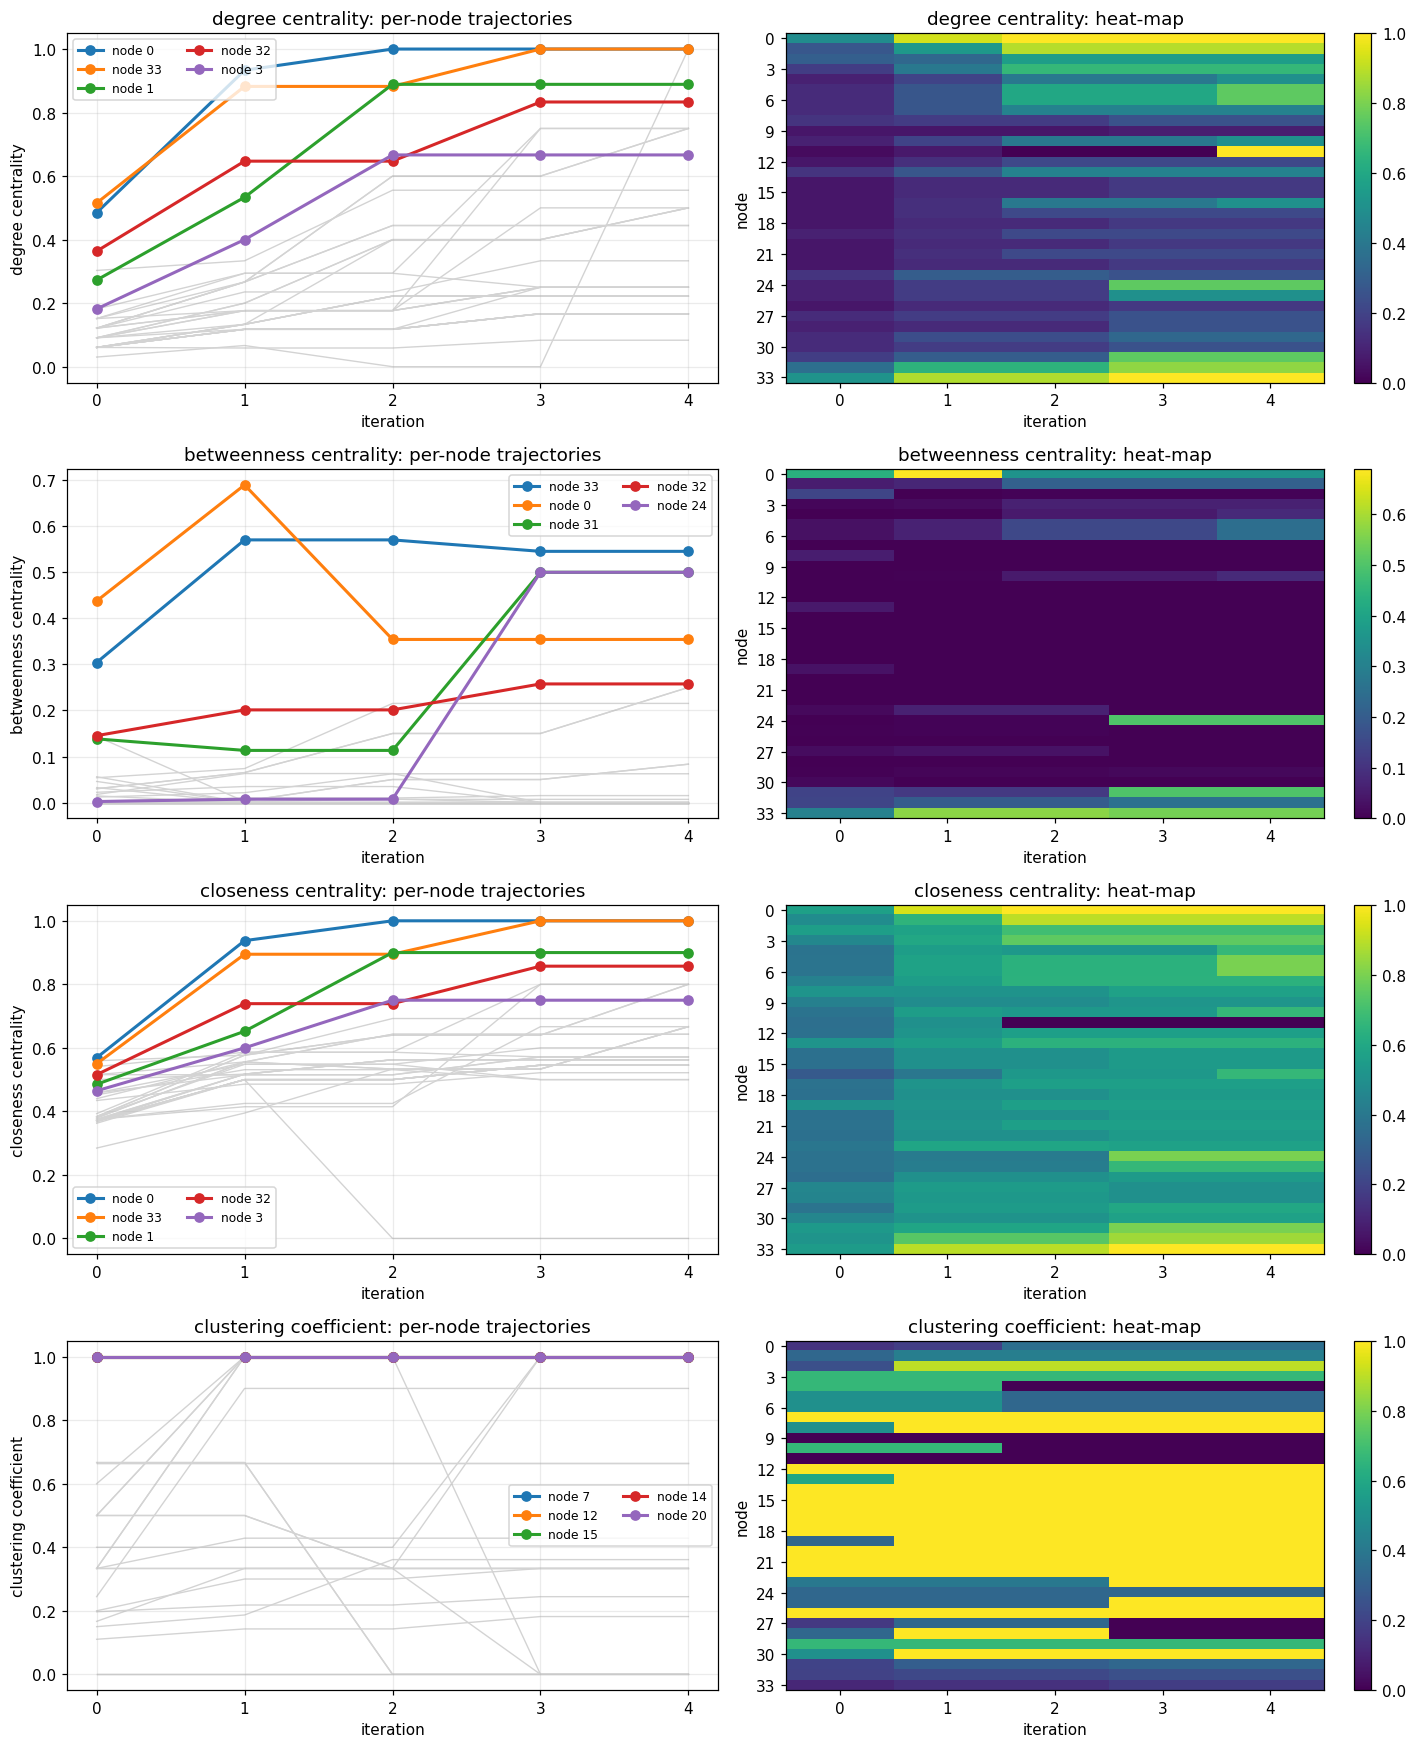

In [11]:
iters = [h["iter"] for h in history]

def metric_matrix(name):
    return np.array([[metric_history[name][it][v] for it in iters] for v in nodes])   # n x T

fig, axes = plt.subplots(len(metric_funcs), 2, figsize=(13, 4.0 * len(metric_funcs)),
                         gridspec_kw={"width_ratios": [1.1, 1]})
for row, name in enumerate(metric_funcs):
    M = metric_matrix(name)
    top = np.argsort(-M.mean(axis=1))[:5]
    ax = axes[row, 0]
    for v in nodes:
        ax.plot(iters, M[v], color="lightgrey", lw=0.9, zorder=1)
    for rank, v in enumerate(top):
        ax.plot(iters, M[v], "o-", color=palette[rank], lw=2, label=f"node {v}", zorder=3)
    ax.set_title(f"{name}: per-node trajectories"); ax.set_xlabel("iteration"); ax.set_xticks(iters)
    ax.set_ylabel(name); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=.25)

    ax = axes[row, 1]
    im = ax.imshow(M, aspect="auto", cmap="viridis")
    ax.set_title(f"{name}: heat-map"); ax.set_xlabel("iteration"); ax.set_ylabel("node")
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(0, n, 3)); plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig("metric_evolution.png", bbox_inches="tight"); plt.show()

In [12]:
# Which nodes stay central? Rank nodes by each metric at every iteration, and
# count how often each node is in the top-5.
from collections import Counter
for name in metric_funcs:
    cnt = Counter()
    for it in iters:
        vals = metric_history[name][it]
        top5 = sorted(vals, key=lambda v: -vals[v])[:5]
        cnt.update(top5)
    print(f"{name:24s} top-5 appearances (out of {len(iters)} iterations):",
          cnt.most_common(6))

# community membership of the hubs at the end
lab_final = community_labels(final_comms)
print("\nFinal community of the key nodes:", {v: f"C{lab_final[v]+1}" for v in (0, 33, 32, 2, 1)})

degree centrality        top-5 appearances (out of 5 iterations): [(33, 5), (0, 5), (32, 5), (1, 5), (3, 2), (2, 1)]
betweenness centrality   top-5 appearances (out of 5 iterations): [(0, 5), (33, 5), (32, 5), (31, 4), (1, 2), (24, 2)]
closeness centrality     top-5 appearances (out of 5 iterations): [(0, 5), (33, 5), (32, 4), (1, 4), (3, 2), (24, 2)]
clustering coefficient   top-5 appearances (out of 5 iterations): [(7, 3), (12, 3), (14, 3), (15, 3), (16, 2), (13, 2)]

Final community of the key nodes: {0: 'C1', 33: 'C3', 32: 'C3', 2: 'C1', 1: 'C1'}


In [13]:
# Table: metrics at the start (whole graph) vs. the end (inside final community), for the hubs
import pandas as pd
last = iters[-1]
rows = []
for v in (0, 33, 32, 2, 1, 31, 8):
    r = {"node": v, "final community": f"C{lab_final[v]+1}", "club": G.nodes[v]["club"]}
    for name in metric_funcs:
        r[name + " (it0)"]  = round(metric_history[name][0][v], 3)
        r[name + f" (it{last})"] = round(metric_history[name][last][v], 3)
    rows.append(r)
pd.DataFrame(rows).set_index("node")

,final community,club,degree centrality (it0),degree centrality (it4),betweenness centrality (it0),betweenness centrality (it4),closeness centrality (it0),closeness centrality (it4),clustering coefficient (it0),clustering coefficient (it4)
node,,,,,,,,,,
0,C1,Mr. Hi,0.485,1.000,0.438,0.354,0.569,1.000,0.150,0.361
33,C3,Officer,0.515,1.000,0.304,0.545,0.550,1.000,0.110,0.182
32,C3,Officer,0.364,0.833,0.145,0.258,0.516,0.857,0.197,0.244
2,C1,Mr. Hi,0.303,0.556,0.144,0.007,0.559,0.692,0.244,0.900
1,C1,Mr. Hi,0.273,0.889,0.054,0.215,0.485,0.900,0.333,0.429
31,C5,Officer,0.182,0.750,0.138,0.500,0.541,0.800,0.200,0.333
8,C3,Mr. Hi,0.152,0.250,0.056,0.000,0.516,0.571,0.500,1.000


## 7. Extra: handout block vs. Newman's generalised matrix
Same recursion with `generalized=True`, to see whether the exact-gain criterion changes the answer.

=== Newman generalised B^(C) ===
iter 1: split group of size 34 (lambda1 = +4.9771) -> 16 + 18;  Q = 0.3715
iter 2: split group of size 16 (lambda1 = +1.1785) -> 7 + 9;  Q = 0.3727
iter 3: split group of size 18 (lambda1 = +0.8594) -> 12 + 6;  Q = 0.3934
  group of size  7: lambda1 = -0.0000 -> indivisible
  group of size  9: lambda1 = +0.0602 -> indivisible
  group of size 12: lambda1 = +0.0000 -> indivisible
  group of size  6: lambda1 = +0.0000 -> indivisible

Final communities:
  C1 (size 7): [0, 4, 5, 6, 10, 11, 16]
  C2 (size 9): [1, 2, 3, 7, 12, 13, 17, 19, 21]
  C3 (size 12): [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  C4 (size 6): [23, 24, 25, 27, 28, 31]

Q (handout block)      = 0.4094  with 5 communities
Q (generalised matrix) = 0.3934  with 4 communities


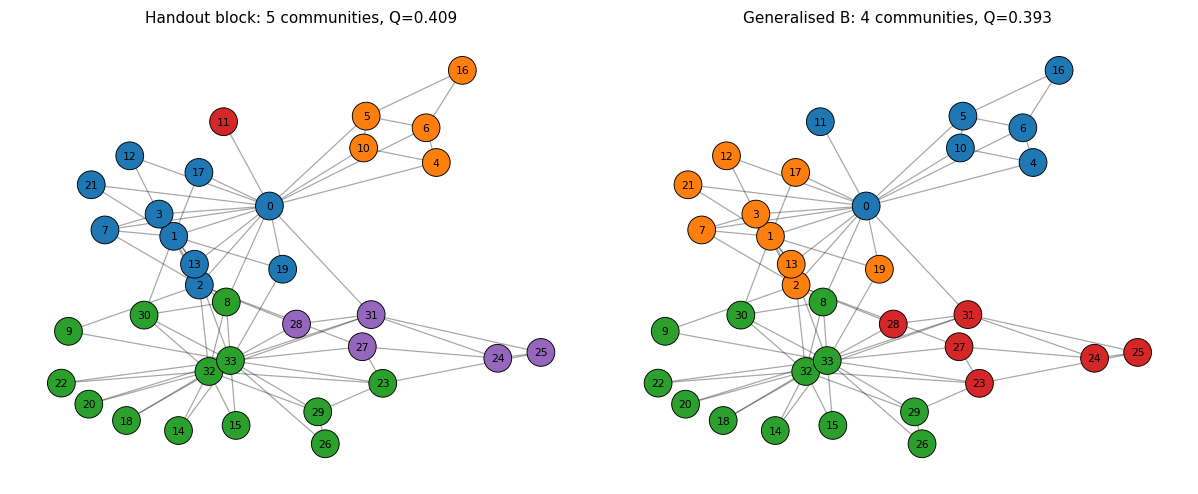

In [14]:
print("=== Newman generalised B^(C) ===")
hist_g, final_g = recursive_bisection(B, m, generalized=True)
print("\nFinal communities:")
for i, c in enumerate(sorted(final_g, key=lambda c: c[0])):
    print(f"  C{i+1} (size {len(c)}): {c}")
Q_plain = modularity(final_comms, B, m)
Q_gen   = modularity(final_g, B, m)
print(f"\nQ (handout block)      = {Q_plain:.4f}  with {len(final_comms)} communities")
print(f"Q (generalised matrix) = {Q_gen:.4f}  with {len(final_g)} communities")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
draw_partition(axes[0], final_comms, f"Handout block: {len(final_comms)} communities, Q={Q_plain:.3f}")
draw_partition(axes[1], final_g,     f"Generalised B: {len(final_g)} communities, Q={Q_gen:.3f}")
plt.tight_layout(); plt.savefig("final_comparison.png", bbox_inches="tight"); plt.show()

## 8. Discussion
*(Numbers below come from the run of this notebook; if you change the seed/layout the picture changes but the numbers do not.)*

**What the algorithm found.** The first spectral split ($\lambda_1 = 4.98$) divides the club 16 / 18 and agrees with the real split on 33 of 34 members (97.1 %). The only error is node 8, who has 3 neighbours in the Officer side (30, 32, 33) and 2 in Mr. Hi's side (0, 2) and so, judged purely on the graph, sits slightly closer to the president's side. Modularity rises with every split (0 → 0.372 → 0.390 → 0.408 → 0.409) and the recursion stops at 5 communities with $Q = 0.409$, higher than the 2-faction ground truth ($Q=0.358$). In other words the graph has finer structure than the two factions: Mr. Hi's side contains a group {4, 5, 6, 10, 16} that hangs off node 0, and the president's side contains {24, 25, 27, 28, 31}. Each split was verified to have positive true $\Delta Q$ (and node 11, a degree-1 node attached to node 0, is peeled off as a singleton in the last step).

**Which nodes stay central.** Across all five iterations, nodes **0** (Mr. Hi) and **33** (the president) are in the top five for degree, betweenness and closeness at every iteration (closeness: 0 and 33 five times, 32 and 1 four times), and node **32** joins them for degree and betweenness at every iteration. Node 31 appears in the betweenness top five in 4 of 5 iterations: it is a broker between the {24, 25, 27, 28} group and the rest. The clustering coefficient behaves the other way round: the high-clustering nodes (7, 12, 14, 15, 16) are low-degree members of tight cliques, not the hubs, and the hubs 0 and 33 have among the *lowest* global clustering (0.15 and 0.11) because their neighbours belong to several different groups.

**How community structure shapes the metrics.** Because the metrics are computed inside each node's community (see Section 5), they show how a node looks "from within its group":
* *Degree and closeness* mostly go **up** (e.g. node 0: degree centrality 0.485 → 1.0, closeness 0.569 → 1.0), because the denominator $n_C-1$ shrinks and communities are dense; a value of 1.0 means the node is adjacent to every other member of its community, i.e. it is the group's centre.
* *Betweenness* separates **local brokers** from **global bridges**. Node 2's betweenness falls from 0.144 to 0.007 and node 0's from 0.438 to 0.354: much of their original betweenness came from shortest paths *between* communities, which disappear once the graph is cut. Node 33 (0.304 → 0.545) and node 31 (0.138 → 0.500) *gain*, since they remain the connectors inside their own communities.
* *Clustering* rises for nodes inside cliquish communities (node 2: 0.244 → 0.900, node 8: 0.500 → 1.000), confirming that the detected groups are locally tightly knit.

**Caveats.** (i) Metrics from different iterations use different normalisers, so cross-iteration comparisons mix a real structural effect with a size effect. (ii) The handout's plain restricted block $B^{(C)}$ is not Newman's exact generalised matrix. Running the generalised version (Section 7) gives 4 communities with $Q=0.393$, while the plain block gives 5 communities with $Q=0.409$; both are close to, but below, the value of about 0.42 usually quoted for the best known partition, because one-shot sign rounding without refinement is greedy. (iii) The true gain after rounding can be negative even when $\lambda_1>0$, which is why the notebook also checks $\Delta Q$ before accepting a split.


## References
* M. E. J. Newman (2006). *Modularity and community structure in networks.* PNAS 103(23):8577–8582.
* W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research 33(4):452–473.
* NetworkX documentation: `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`.